# Hands-On Session_week1 -

## Part 1

### 1-1 -Prediction before calculation
Before running any calculations, predict qualitatively how changing ϵ and σ should affect:
 the equilibrium separation r0;
 the depth of the potential minimum U(r0);
 the local pair stiffness kpair.

Equilibrium separation ($r_0$): Increasing $\sigma$ increases $r_0$, while changing $\epsilon$ does not affect it.

Potential minimum ($U(r_0)$): Increasing $\epsilon$ makes the minimum deeper (more negative); changing $\sigma$ does not affect its depth.

Pair stiffness ($k_{\text{pair}}$): Increasing $\epsilon$ increases stiffness, and increasing $\sigma$ decreases stiffness.


### 1.2 Numerical comparison:


In [37]:
## Lenard-Jones potential equation
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
def lj_energy(r,e = 1,s = 1):
    U = 4 * e * ((s/r)**12 - (s/r)**6)
    return U

r = np.linspace(0.95,3.0,1000)
# evaluate U(r)
U  = lj_energy(r,s = 1)


  Model  Epsilon  Sigma      r0  U(r0)    k_pair
0     A      1.0    1.0  1.1228   -1.0   56.7618
1     B      0.5    1.0  1.1228   -0.5   28.3809
2     C      2.0    1.0  1.1228   -2.0  113.5236
3     D      1.0    1.2  1.3477   -1.0   39.1968


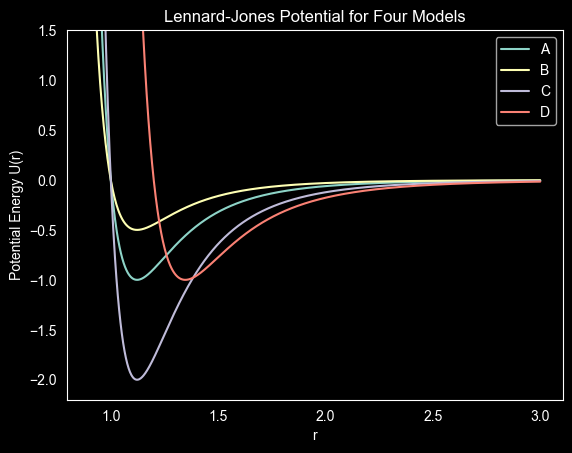

In [3]:

models = {
    "A": (1.0, 1.0),
    "B": (0.5, 1.0),
    "C": (2.0, 1.0),
    "D": (1.0, 1.2)
}

results = []

h = 1e-4
r = np.linspace(0.9, 3.0, 1000)

for name, (e, s) in models.items():

    U = lj_energy(r, e=e, s=s)

    min_idx = np.argmin(U)
    r0 = r[min_idx]
    U_min = lj_energy(r0, e=e, s=s)

    U_0 = lj_energy(r0, e=e, s=s)
    U_plus = lj_energy(r0 + h, e=e, s=s)
    U_minus = lj_energy(r0 - h, e=e, s=s)

    k_pair = (U_plus - 2 * U_0 + U_minus) / h**2

    results.append([name, e, s, r0, U_min, k_pair])

df = pd.DataFrame(results, columns=[
    "Model", "Epsilon", "Sigma", "r0", "U(r0)", "k_pair"
])

print(df.round(4))


r = np.linspace(0.9, 3.0, 1000)

for name, (e, s) in models.items():
    U = lj_energy(r, e=e, s=s)
    plt.plot(r, U, label=name)

plt.xlabel("r")
plt.ylabel("Potential Energy U(r)")
plt.ylim(-2.2, 1.5)
plt.title("Lennard-Jones Potential for Four Models")
plt.legend()
plt.grid()
plt.show()

### 1.3 Interpretation–

a. Which parameter primarily sets the characteristic interaction distance?
\\(\sigma\\) primarily sets the characteristic interaction distance.

b. Which parameter primarily sets the interaction-energy scale? \\(\epsilon\\) primarily sets the interaction-energy scale.

c. Is a deeper potential-energy minimum necessarily associated with a larger local stiffness? Use
your results to justify your answer

No. While increasing the well depth parameter $\epsilon$ increases both depth and stiffness, pair stiffness also scales inversely with spatial size ($k_{\text{pair}} \propto \frac{1}{\sigma^2}$).A system can have a deep potential minimum (large $\epsilon$) yet low stiffness if the interaction distance is large (large $\sigma$). Conversely, a shallower minimum (small $\epsilon$) can have high stiffness if the interaction distance is small (small $\sigma$). Therefore, well depth alone does not uniquely dictate local stiffness.





## Part 2 -  When is the harmonic approximation valid?

### 2.1 Exact and harmonic energy:


K_pair (Curvature, Stiffness): 57.1464519039111


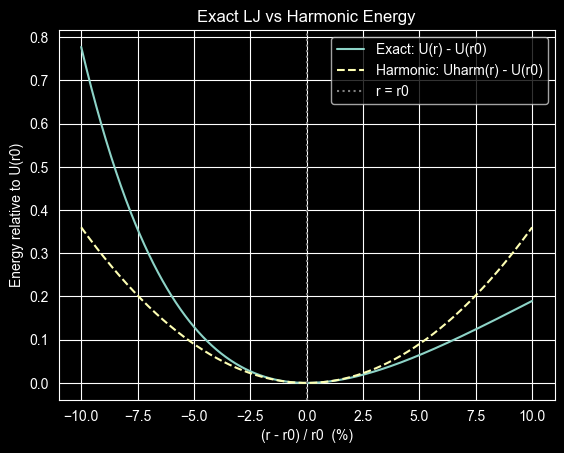

In [14]:
# part 1
e = 1
s = 1
r_0 = 2 **(1/6)

h = 1e-4
U_0 = lj_energy(r_0,e=e,s=s)
U_plus = lj_energy(r_0+h ,e=e,s=s)
U_minus =  lj_energy(r_0-h ,e=e,s=s)

k_pair = (U_plus - 2 * U_0 + U_minus) / h ** 2
print(f"K_pair (Curvature, Stiffness): {k_pair}")

#part 2
deformation = np.linspace(-0.10,0.10,1000)
r = r_0 * (1 + deformation)

U_exact = lj_energy(r,e=e,s=s) - U_0

# U_harm - U_0 = 1/2k (r-r0) **2
U_harm = 0.5 * k_pair * (r - r_0)**2

# Plot
plt.plot(deformation * 100, U_exact, label = "Exact: U(r) - U(r0)")
plt.plot(deformation * 100, U_harm, linestyle = "--", label = "Harmonic: Uharm(r) - U(r0)")
plt.axvline(0, color = "gray", linestyle = ":", label = "r = r0")
plt.xlabel("(r - r0) / r0  (%)")
plt.ylabel("Energy relative to U(r0)")
plt.title("Exact LJ vs Harmonic Energy")
plt.legend()
plt.show()

### 2.2 Exact and harmonic force:

In [16]:
## Lenard_Jones Force
def lj_force (r,e = 1,s = 1):
    F = (24 ** e/r) * (2 * (s/r)**12 - (s/r)**6)
    return F

r = np.linspace(.95,3.0,1000)

# evaluate F
F = lj_force(r,e = 1,s = 1)

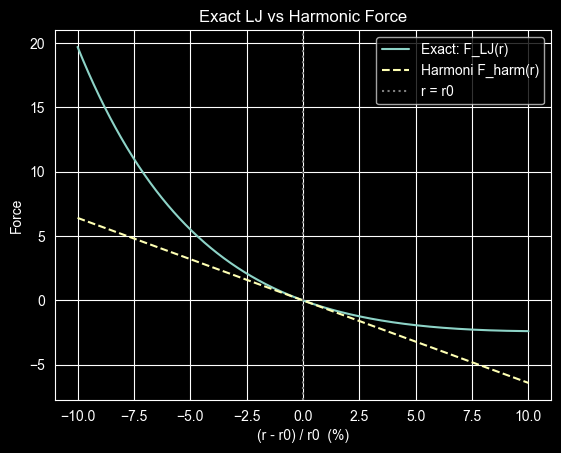

In [20]:
r = r_0 * (1 + deformation)
F_LJ = lj_force(r,e = 1,s = 1)
F_harm = -k_pair * (r - r_0)

plt.plot(deformation * 100, F_LJ, label = "Exact: F_LJ(r)")
plt.plot(deformation * 100, F_harm, linestyle = "--", label = "Harmoni F_harm(r)")
plt.axvline(0, color = "gray", linestyle = ":", label = "r = r0")
plt.xlabel("(r - r0) / r0  (%)")
plt.ylabel("Force")
plt.title("Exact LJ vs Harmonic Force")
plt.legend()
plt.show()


In [24]:
# Calculate the percentage difference in the magnitude of the forces at the following bond strains:
# −5%, −2%, −1%, +1%, +2%, +5%.
# Report the values in a table. For a nonzero force, define

strains = np.array([-0.05, -0.02, -0.01, 0.01, 0.02, 0.05])
r_s = r_0 * (1 + strains)

F_LJ_s = lj_force(r_s,e = 1,s = 1)
F_harm_s = -k_pair * (r_s - r_0)

rel_error = np.abs(np.abs(F_harm_s) - np.abs(F_LJ_s)) / np.abs(F_LJ_s) * 100

table = pd.DataFrame({
    "Strain (%)": strains * 100,
    "r": r_s,
    "F_LJ": F_LJ_s,
    "F_harm": F_harm_s,
    "Relative error (%)": rel_error
})
table


,Strain (%),r,F_LJ,F_harm,Relative error (%)
0,-5.0,1.066339,5.516936,3.207236,41.865629
1,-2.0,1.100013,1.586995,1.282894,19.162023
2,-1.0,1.111237,0.712944,0.641447,10.028351
3,1.0,1.133687,-0.577895,-0.641447,10.997150
4,2.0,1.144911,-1.042647,-1.282894,23.042055
5,5.0,1.178585,-1.928190,-3.207236,66.334058


### 2.3 Interpretation

a. Around what deformation range would you regard the harmonic approximation as reasonably
accurate for this model? State the criterion you used.

b. Is the deviation from harmonic behavior symmetric between compression and extension?

c. Explain physically why a second-order approximation around r0 becomes progressively less
reliable as the system moves away from equilibrium

Answers:

a. I would consider the harmonic approximation reasonably accurate within approximately ±2% deformation, using a relative energy error below 5% as the criterion.

b. No. The deviation is asymmetric because the Lennard-Jones potential rises steeply during compression but increases more gradually during extension.

c. The second-order approximation only captures the local curvature near equilibrium. Farther away, higher-order nonlinear terms become more significant, making the harmonic approximation less reliable.


## Part 3– From atomic stiffness to an effective material modulus

### 3-1 - Chain stiffness and system size

In [41]:
r_0 = 2 **(1/6)
h = 1e-4
U_0 = lj_energy(r_0,e=1,s = 1)
U_plus = lj_energy(r_0+h ,e=1,s = 1)
U_minus =  lj_energy(r_0-h ,e=1,s = 1)
k_pair = (U_plus - 2 * U_0 + U_minus) / h ** 2

N_list = [5,10,20,40,80]
strain = np.linspace(-0.03,.03,301)

results = []

for N in N_list:
    L0 = (N-1) * r_0
    L = L0 * (1 + strain)
    r_nn = L / (N-1)
    U_tot = (N-1) * lj_energy(r_nn, e=1, s=1)

    P = np.gradient(U_tot,L)
    delta_L = L - L0

    mask = np.abs(strain) <= 0.01
    coeff = np.polyfit(delta_L[mask],P[mask],1)
    K_fit = coeff[0]

    K_pred = k_pair / (N - 1)

    rel_diff = np.abs(K_fit - K_pred) / K_pred * 100

    results.append([N, L0, K_fit, K_pred, rel_diff])

table = pd.DataFrame(results, columns = ["N","L0","K_chain_fit","K_chain_pred","Relative difference (%)"])
table

,N,L0,K_chain_fit,K_chain_pred,Relative difference (%)
0,5,4.489848,14.309627,14.286613,0.161087
1,10,10.102158,6.359834,6.349606,0.161087
2,20,21.326779,3.012553,3.007708,0.161087
3,40,43.776020,1.467654,1.465294,0.161087
4,80,88.674502,0.724538,0.723373,0.161087


### 3.2 Test the scaling law:


Fitted slope: 57.23850734572186
Fitted intercept: 6.916898805911478e-14
k_pair: 57.1464519039111
Relative difference (slope vs k_pair): 0.1611 %


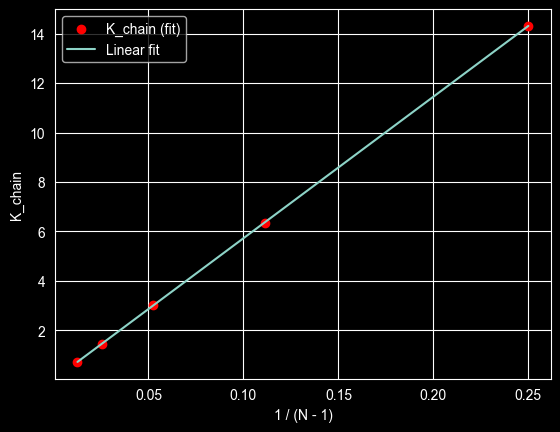

In [42]:
N_arr = np.array(N_list)
x = 1 / (N_arr - 1)
K_fit_arr = table["K_chain_fit"].values

coeff = np.polyfit(x, K_fit_arr, 1)
slope = coeff[0]
intercept = coeff[1]

rel_diff_slope = np.abs(slope - k_pair) / k_pair * 100

print(f"Fitted slope: {slope}")
print(f"Fitted intercept: {intercept}")
print(f"k_pair: {k_pair}")
print(f"Relative difference (slope vs k_pair): {rel_diff_slope:.4f} %")

# Plot
plt.scatter(x, K_fit_arr, color = "red", label = "K_chain (fit)")
plt.plot(x, slope * x + intercept, label = "Linear fit")
plt.xlabel("1 / (N - 1)")
plt.ylabel("K_chain")
plt.legend()
plt.show()

### 3.3 From spring stiffness to an effective modulus

In [36]:
A = 1

table["E_eff"] = table["K_chain_fit"] * table["L0"] / A

E_pred = k_pair * r_0 / A

table["E_pred"] = E_pred
table["Relative difference (%)"] = np.abs(table["E_eff"] - E_pred) / E_pred * 100


print(f"k_pair * r0 / A = {E_pred}")
table[["N","L0","K_chain_fit","E_eff","E_pred","Relative difference (%)"]]

k_pair * r0 / A = 64.14472345767712


,N,L0,K_chain_fit,E_eff,E_pred,Relative difference (%)
0,5,4.489848,14.309627,64.248052,64.144723,0.161087
1,10,10.102158,6.359834,64.248052,64.144723,0.161087
2,20,21.326779,3.012553,64.248052,64.144723,0.161087
3,40,43.776020,1.467654,64.248052,64.144723,0.161087
4,80,88.674502,0.724538,64.248052,64.144723,0.161087


3.4 Interpretation

Why K_chain decreases with N: The bonds are in series, so each one carries the same force and the extensions add up. A longer chain stretches more under the same force, so K_chain = k_pair/(N−1) goes down.

Why E_eff is roughly independent of N: E_eff = K_chain · L0 / A, and L0 = (N−1) r0 grows by the same factor that K_chain shrinks. The (N−1) cancels, leaving E_eff = k_pair · r0 / A, which depends only on the bond (k_pair, r0) and the area. Our values are all ≈ 64.25, a constant 0.16% above the prediction.

Distinction: K_chain is a structural stiffness. It depends on the size and geometry of the specific object (here, its length). E_eff is a material property. Normalizing by geometry (L0 and A) removes the size dependence and leaves a number that describes the material itself, which is the idea behind Young's modulus.

## Part 4– What can this model actually tell us?

4.1 Model assumptions

Identify three assumptions or simplifications in the one-dimensional chain that would have to
be reconsidered before using molecular simulation to predict the Young’s modulus of a real material.
For each one, write one sentence explaining why it matters

1. One-dimensional geometry. A real solid is three-dimensional, and the area A here is just assumed, so a real model needs the actual atomic arrangement and cross-section to define stress, plus Poisson (lateral) effects.

2. Nearest-neighbor interactions only. In a real material each atom interacts with many neighbors, which adds to the effective stiffness, so ignoring them gives the wrong k_pair and modulus.

3. Zero temperature and a perfect, uniform structure. Real materials have thermal vibrations, defects, grain boundaries and different bond types, which soften the response and make the modulus depend on temperature and microstructure.

4.2 Parameters, observables, and assumptions


1. ε: model parameter. It is an input that sets the depth of the potential well (the bond energy scale), and we choose it (ε = 1) rather than compute it. In a real study it would be fitted to experiment or quantum calculations.

2. r0: calculated observable (derived from the parameters). It is not set directly. It comes from locating the minimum of U(r), and it equals 2^(1/6)σ. It could reasonably also be called a parameter, since σ is the input and r0 follows from it.

3. K_chain: calculated observable. We obtain it from the force-extension response (the linear fit), and it depends on both the potential and the chain size.

4. Nearest-neighbor interactions only: model assumption. It is a simplification of the physics that we build into the model, not a number we choose or a quantity we measure.

5. N: model parameter (a simulation setup choice). We choose the number of atoms as an input. It describes system size, not material physics, which is why E_eff should not depend on it.

4.3 Engineering interpretation

A simulation doesn't just reproduce an experiment. It replaces an unknown macroscopic modulus with a microscopic model whose inputs and assumptions must be justified. Here we never assumed a Young's modulus. We computed k_pair ≈ 57.1 from the Lennard-Jones curvature and obtained E_eff = k_pair · r0 / A ≈ 64.2, independent of N. But this depends on the model: it is 1D, nearest-neighbor only, at zero temperature, and harmonic only for about ±1% strain. Changing ε, σ or the interaction range would change E_eff, so the uncertainty moves from the modulus to the microscopic parameters and assumptions.